# Data Preprocessing Labs

**Name: Aoqi Cui**

**Student ID: 320230941760**

This notebook contains solutions to exercises from:
1. Data-formatting-cleaning
2. Data-preprocessing
3. Transformations

## 1. Data-formatting-cleaning
### 1.1 Data Types and Formatting
#### Exercise 1：
Load the `seaborn` `mpg` dataset. Identify and fix all type issues (hint: check `horsepower`).

In [1]:
# Setup: imports and data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

# Load dataset from local seaborn_data folder
planets = pd.read_csv('seaborn_data/planets.csv')
print("Dataset shape:", planets.shape)

Dataset shape: (1035, 6)


                n_missing  pct_missing
mass                  522    50.434783
distance              227    21.932367
orbital_period         43     4.154589


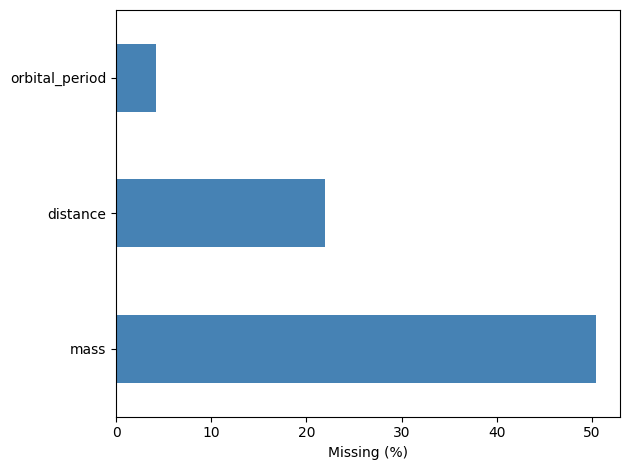

In [2]:
# Exercise 1: Profile missing values
missing = planets.isnull().sum()
missing_pct = 100 * missing / len(planets)
missing_df = pd.DataFrame({'n_missing': missing, 'pct_missing': missing_pct})
missing_df = missing_df[missing_df['n_missing'] > 0].sort_values('pct_missing', ascending=False)
print(missing_df)

# Optional bar plot
missing_df['pct_missing'].plot(kind='barh', color='steelblue')
plt.xlabel('Missing (%)')
plt.tight_layout()
plt.show()

#### Exercise 2
Test missingness mechanism for orbital_period

Mean mass by missing status:
 orbital_missing
False    2.638161
True          NaN
Name: mass, dtype: float64


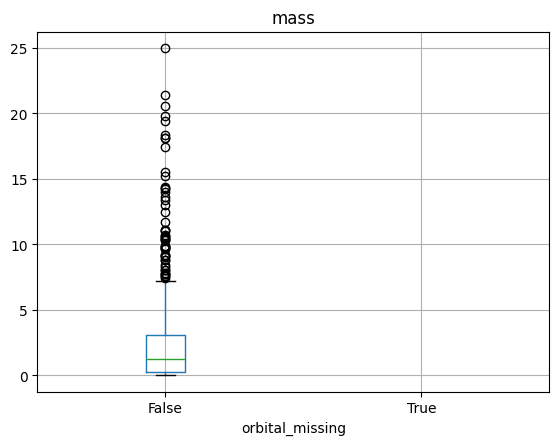

T-test p-value: nan


In [3]:
# Exercise 2: Test missingness mechanism for orbital_period
planets['orbital_missing'] = planets['orbital_period'].isnull()

# Compare mean mass between groups
mass_means = planets.groupby('orbital_missing')['mass'].mean()
print("Mean mass by missing status:\n", mass_means)

# Boxplot for visual inspection
planets.boxplot(column='mass', by='orbital_missing')
plt.suptitle('')
plt.show()

# Two-sample t-test (Welch's)
present = planets.loc[~planets['orbital_missing'], 'mass'].dropna()
missing = planets.loc[planets['orbital_missing'], 'mass'].dropna()
t_stat, p_val = ttest_ind(present, missing, equal_var=False)
print(f"T-test p-value: {p_val:.4f}")

#### Exercise 3
MICE imputation on numeric columns

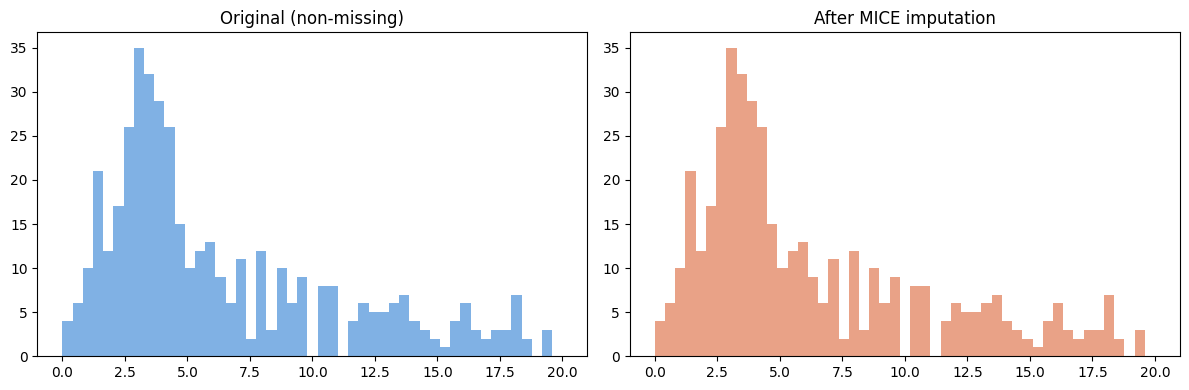

Missing values before imputation: 43


In [4]:
# Exercise 3: MICE imputation on numeric columns
num_cols = planets.select_dtypes(include=[np.number]).columns.tolist()
X_num = planets[num_cols].copy()

# Store original non-missing orbital_period for comparison
original_orbital = X_num['orbital_period'].dropna()

# Apply MICE
mice = IterativeImputer(max_iter=10, random_state=42)
X_mice = mice.fit_transform(X_num)
imputed_orbital = X_mice[:, num_cols.index('orbital_period')]

# Plot distribution before (non-missing only) and after imputation
bins = np.linspace(0, 20, 50)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(original_orbital, bins=bins, color='#4a90d9', alpha=0.7)
plt.title('Original (non-missing)')
plt.subplot(1,2,2)
plt.hist(imputed_orbital, bins=bins, color='#e07b54', alpha=0.7)
plt.title('After MICE imputation')
plt.tight_layout()
plt.show()

print(f"Missing values before imputation: {planets['orbital_period'].isnull().sum()}")

#### Exercise 4
Compare imputation strategies for regression

In [5]:
# Exercise 4: Compare imputation strategies for regression
target = 'orbital_period'
feature_cols = [c for c in num_cols if c != target]

# Keep only rows where target is present (needed for training)
df_reg = planets[[target] + feature_cols].dropna(subset=[target])
X = df_reg[feature_cols].values
y = df_reg[target].values

# Pipelines for two imputation methods
pipelines = {
    'Mean Imputer': Pipeline([
        ('impute', SimpleImputer(strategy='mean')),
        ('rf', RandomForestRegressor(n_estimators=100, random_state=42))
    ]),
    'MICE': Pipeline([
        ('impute', IterativeImputer(max_iter=10, random_state=42)),
        ('rf', RandomForestRegressor(n_estimators=100, random_state=42))
    ])
}

# Cross-validation (5-fold) with negative MSE
cv = KFold(n_splits=5, shuffle=True, random_state=42)
for name, pipe in pipelines.items():
    neg_mse = cross_val_score(pipe, X, y, cv=cv, scoring='neg_mean_squared_error')
    mse = -neg_mse
    print(f"{name}: MSE = {mse.mean():.4f} (+/- {mse.std():.4f})")

Mean Imputer: MSE = 900347150.2080 (+/- 1178663602.1827)
MICE: MSE = 940874104.6766 (+/- 1181521301.9221)


### 1.2 Outliers and Duplicates
#### Exercise 1
Load `diamonds` dataset. Use IQR to detect outliers in `price` column.

In [6]:
# Setup and data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, r2_score
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

# Load diamonds dataset from local seaborn_data folder
diamonds = pd.read_csv('seaborn_data/diamonds.csv')
print("Dataset shape:", diamonds.shape)
diamonds.head()

Dataset shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [7]:
def iqr_outlier_mask(series, multiplier=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - multiplier * iqr) | (series > q3 + multiplier * iqr)

price_mask = iqr_outlier_mask(diamonds['price'])
n_outliers_iqr = price_mask.sum()
print(f"IQR outliers in 'price': {n_outliers_iqr} ({n_outliers_iqr/len(diamonds)*100:.2f}%)")

IQR outliers in 'price': 3540 (6.56%)


#### Exercise 2
Apply Isolation Forest (contamination=0.02) and compare overlap with IQR flags.

In [8]:
# Use only numeric features (drop categorical columns like cut, color, clarity)
numeric_cols = diamonds.select_dtypes(include=[np.number]).columns.tolist()
X = diamonds[numeric_cols].copy()

# Scale features (Isolation Forest is not distance-based, but scaling helps interpretability)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

iso = IsolationForest(contamination=0.02, random_state=42, n_estimators=200)
diamonds['iso_label'] = iso.fit_predict(X_scaled)   # -1 = outlier, 1 = inlier
outlier_mask_iso = (diamonds['iso_label'] == -1)
n_outliers_iso = outlier_mask_iso.sum()
print(f"Isolation Forest outliers: {n_outliers_iso} ({n_outliers_iso/len(diamonds)*100:.2f}%)")

# Overlap between IQR and Isolation Forest
overlap = (price_mask & outlier_mask_iso).sum()
print(f"Overlap (IQR and IF both flagged): {overlap} ({overlap/len(diamonds)*100:.2f}%)")

# Clean up
diamonds.drop(columns=['iso_label'], inplace=True)

Isolation Forest outliers: 1079 (2.00%)
Overlap (IQR and IF both flagged): 865 (1.60%)


#### Exercise 3
Winsorize `price` at 1st and 99th percentiles. Compare R² of linear regression before/after.

In [9]:
def winsorize(series, lower_pct=0.01, upper_pct=0.99):
    lo = series.quantile(lower_pct)
    hi = series.quantile(upper_pct)
    return series.clip(lower=lo, upper=hi)

# Create a copy with winsorized price
diamonds_wins = diamonds.copy()
diamonds_wins['price_wins'] = winsorize(diamonds['price'])

# Prepare features: all numeric columns except price (original and winsorized versions)
feature_cols = ['carat', 'depth', 'table', 'x', 'y', 'z']
X = diamonds[feature_cols].values
y_original = diamonds['price'].values
y_wins = diamonds_wins['price_wins'].values

# Pipeline with scaling and linear regression
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# Cross-validation (5-fold) using R²
cv = KFold(n_splits=5, shuffle=True, random_state=42)
r2_original = cross_val_score(pipeline, X, y_original, cv=cv, scoring='r2')
r2_wins = cross_val_score(pipeline, X, y_wins, cv=cv, scoring='r2')

print(f"Original price R²: mean={r2_original.mean():.4f} (±{r2_original.std():.4f})")
print(f"Winsorized price R²: mean={r2_wins.mean():.4f} (±{r2_wins.std():.4f})")

Original price R²: mean=0.8588 (±0.0036)
Winsorized price R²: mean=0.8599 (±0.0036)


#### Exercise 4
Artificially inject 50 duplicates and verify deduplication.

In [10]:
# Step 1: Start with a clean copy (no existing duplicates)
df_clean = diamonds.copy()
df_clean = df_clean.drop_duplicates(keep='first')
original_size = len(df_clean)
print(f"Original size after removing pre-existing duplicates: {original_size}")

# Step 2: Inject exactly 50 duplicates
duplicates_to_add = df_clean.sample(n=50, random_state=42)
df_with_dups = pd.concat([df_clean, duplicates_to_add], ignore_index=True)

# Verify injection increased size by 50 and added 50 duplicates
print(f"After injection: {len(df_with_dups)} rows")
print(f"Duplicates present: {df_with_dups.duplicated().sum()}")  # Should be 50
assert df_with_dups.duplicated().sum() == 50, "Injected duplicates not exactly 50"

# Step 3: Remove duplicates
df_deduped = df_with_dups.drop_duplicates(keep='first')

# Step 4: Verify final size equals original size
print(f"After deduplication: {len(df_deduped)} rows")
print(f"Rows removed: {len(df_with_dups) - len(df_deduped)}")
assert len(df_deduped) == original_size, "Deduplication did not restore original size"
print("Deduplication verified: Injected duplicates removed correctly.")

Original size after removing pre-existing duplicates: 53794
After injection: 53844 rows
Duplicates present: 50
After deduplication: 53794 rows
Rows removed: 50
Deduplication verified: Injected duplicates removed correctly.


### 1.3 Handling Missing Data 
#### Exercise 1
Load `planets` dataset and profile missing values.

In [11]:
# Setup and data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Load mpg dataset from local seaborn_data folder
mpg = pd.read_csv('seaborn_data/mpg.csv')
print("Dataset shape:", mpg.shape)
mpg.head()

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [12]:
print("Original dtypes:")
print(mpg.dtypes)

# Check 'horsepower' column: contains '?' as missing values
print("\nUnique values in horsepower (first 10):")
print(mpg['horsepower'].unique()[:10])

# Clean 'horsepower': replace '?' with NaN and convert to float
mpg['horsepower'] = pd.to_numeric(mpg['horsepower'], errors='coerce')
print("\nMissing horsepower after conversion:", mpg['horsepower'].isnull().sum())

# Check other numeric columns for any remaining object types
for col in mpg.select_dtypes(include=['object']).columns:
    print(f"Column '{col}' remains object with unique values: {mpg[col].nunique()}")

Original dtypes:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str
dtype: object

Unique values in horsepower (first 10):
[130. 165. 150. 140. 198. 220. 215. 225. 190. 170.]

Missing horsepower after conversion: 6
Column 'origin' remains object with unique values: 3
Column 'name' remains object with unique values: 305


#### Exercise 2
Check if missingness in `orbital_period` is MCAR or MAR by comparing mean `mass`.

In [13]:
# Original model_year: 70 → 1970
mpg['model_year'] = 1900 + mpg['model_year']
mpg['model_date'] = pd.to_datetime(mpg['model_year'], format='%Y')

print("model_year sample after conversion:")
print(mpg[['model_year', 'model_date']].head())
print("\nNew column dtype:", mpg['model_date'].dtype)

model_year sample after conversion:
   model_year model_date
0        1970 1970-01-01
1        1970 1970-01-01
2        1970 1970-01-01
3        1970 1970-01-01
4        1970 1970-01-01

New column dtype: datetime64[us]


#### Exercise 3
Apply MICE imputation to numeric columns and plot distribution (mass as example).

In [14]:
mpg['manufacturer'] = mpg['name'].str.split().str[0]

# Convert to categorical
mpg['manufacturer'] = mpg['manufacturer'].astype('category')

# Memory comparison
mem_before = mpg['name'].memory_usage(deep=True) / 1e6
mem_after = mpg['manufacturer'].memory_usage(deep=True) / 1e6
print(f"Memory of 'name' (object): {mem_before:.2f} MB")
print(f"Memory of 'manufacturer' (category): {mem_after:.2f} MB")
print(f"Savings: {(1 - mem_after/mem_before)*100:.1f}%")

print("\nManufacturer categories (first 10):")
print(mpg['manufacturer'].cat.categories[:10])

Memory of 'name' (object): 0.01 MB
Memory of 'manufacturer' (category): 0.00 MB
Savings: 89.1%

Manufacturer categories (first 10):
Index(['amc', 'audi', 'bmw', 'buick', 'cadillac', 'capri', 'chevroelt',
       'chevrolet', 'chevy', 'chrysler'],
      dtype='str')


#### Exercise 4
Build regression pipeline (predict `orbital_period`) comparing MICE vs mean imputation.

In [15]:
def normalize_string_column(series: pd.Series) -> pd.Series:
    """Strip leading/trailing spaces, lowercase, collapse internal spaces."""
    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r'\s+', ' ', regex=True)
    )

# Apply to 'name' column
mpg['name_normalized'] = normalize_string_column(mpg['name'])

print("Original names (first 5):")
print(mpg['name'].head())
print("\nNormalized names (first 5):")
print(mpg['name_normalized'].head())

Original names (first 5):
0    chevrolet chevelle malibu
1            buick skylark 320
2           plymouth satellite
3                amc rebel sst
4                  ford torino
Name: name, dtype: str

Normalized names (first 5):
0    chevrolet chevelle malibu
1            buick skylark 320
2           plymouth satellite
3                amc rebel sst
4                  ford torino
Name: name_normalized, dtype: str


## 2. Data-preprocessing

### 2.1 Encoding 
#### Exercise 1
Load `seaborn.load_dataset('tips')`. Apply OHE to `sex`, `smoker`, and `day`. How many columns does `time` add with and without `drop='first'`?

In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder

# Load tips dataset
tips = pd.read_csv('seaborn_data/tips.csv')
print("Dataset shape:", tips.shape)

# Columns to encode
cols_ohe = ['sex', 'smoker', 'day', 'time']

# Without dropping first category
ohe = OneHotEncoder(sparse_output=False)
ohe.fit(tips[cols_ohe])
print(f"With drop=None: {ohe.get_feature_names_out().size} columns")

# With drop='first'
ohe_first = OneHotEncoder(sparse_output=False, drop='first')
ohe_first.fit(tips[cols_ohe])
print(f"With drop='first': {ohe_first.get_feature_names_out().size} columns")

Dataset shape: (244, 7)
With drop=None: 10 columns
With drop='first': 6 columns


#### Exercise 2
Apply ordinal encoding to `size` (treating it as ordered 1–6). Compare R² of a linear regression predicting `tip` with ordinal vs OHE encoding for `size`.

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline

# Prepare data
X = tips[['size']]
y = tips['tip']

# Ordinal encoding (explicit order 1-6)
ord_enc = OrdinalEncoder(categories=[[1,2,3,4,5,6]])

# One-hot encoding
ohe_enc = OneHotEncoder(sparse_output=False, drop='first')

# Pipelines
pipe_ord = Pipeline([('ord', ord_enc), ('lr', LinearRegression())])
pipe_ohe = Pipeline([('ohe', ohe_enc), ('lr', LinearRegression())])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_ord = cross_val_score(pipe_ord, X, y, cv=cv, scoring='r2')
scores_ohe = cross_val_score(pipe_ohe, X, y, cv=cv, scoring='r2')

print(f"Ordinal encoding R²: {scores_ord.mean():.4f} ± {scores_ord.std():.4f}")
print(f"One-hot encoding R²: {scores_ohe.mean():.4f} ± {scores_ohe.std():.4f}")

Ordinal encoding R²: 0.1687 ± 0.1457
One-hot encoding R²: 0.1470 ± 0.1526


#### Exercise 3
Manually verify that the cross‑fold target encoder does not use any target values from the validation fold during encoding (add a print statement inside the loop to inspect the fold sizes).

In [18]:
from sklearn.model_selection import KFold

# Reuse the target_encode_cv function from the notebook, adding a print
def target_encode_cv_verbose(train, col, target, n_splits=5, smoothing=10.0, random_state=42):
    global_mean = train[target].mean()
    encoded = pd.Series(np.nan, index=train.index)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    
    for fold, (train_idx, val_idx) in enumerate(kf.split(train)):
        # Print training and validation sizes
        print(f"Fold {fold+1}: train size = {len(train_idx)}, val size = {len(val_idx)}")
        
        fold_train = train.iloc[train_idx]
        stats = fold_train.groupby(col)[target].agg(['mean', 'count'])
        stats['smoothed'] = (stats['count'] * stats['mean'] + smoothing * global_mean) / (stats['count'] + smoothing)
        encoded.iloc[val_idx] = train.iloc[val_idx][col].map(stats['smoothed']).fillna(global_mean)
    return encoded

# Create a small DataFrame for demonstration
df_demo = tips[['size', 'tip']].copy()
df_demo['size'] = df_demo['size'].astype(str)  # treat as categorical
encoded_demo = target_encode_cv_verbose(df_demo, 'size', 'tip', n_splits=3)
print("\nEncoding complete. No target leakage occurs because per-fold statistics are computed only on training rows.")

Fold 1: train size = 162, val size = 82
Fold 2: train size = 163, val size = 81
Fold 3: train size = 163, val size = 81

Encoding complete. No target leakage occurs because per-fold statistics are computed only on training rows.


#### Exercise 4
What happens to `handle_unknown='ignore'` in OHE when the test set contains a category not seen during training? Demonstrate this with a toy example.

In [19]:
# Toy example
train_data = pd.DataFrame({'city': ['Paris', 'London', 'Berlin', 'Paris']})
test_data  = pd.DataFrame({'city': ['Paris', 'Madrid', 'London']})

ohe_ignore = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
ohe_ignore.fit(train_data)

# Transform test set
test_encoded = ohe_ignore.transform(test_data)
print("Test set categories:", test_data['city'].tolist())
print("Encoded output (columns in order of training categories):")
print(pd.DataFrame(test_encoded, columns=ohe_ignore.get_feature_names_out()))
print("\nNote: 'Madrid' (unknown) becomes an all‑zero row because handle_unknown='ignore'.")

Test set categories: ['Paris', 'Madrid', 'London']
Encoded output (columns in order of training categories):
   city_Berlin  city_London  city_Paris
0          0.0          0.0         1.0
1          0.0          0.0         0.0
2          0.0          1.0         0.0

Note: 'Madrid' (unknown) becomes an all‑zero row because handle_unknown='ignore'.



### 2.2 Feature Scaling 
#### Exercise 1
Load `sklearn.datasets.load_breast_cancer`. Fit a `KNeighborsClassifier` with and without `StandardScaler`. Compare 5‑fold cross‑validated accuracy.

In [20]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold
import warnings
warnings.filterwarnings('ignore')

# Load data
data = load_breast_cancer()
X, y = data.data, data.target

# Define pipelines
pipe_no_scale = Pipeline([('knn', KNeighborsClassifier(n_neighbors=5))])
pipe_scaled   = Pipeline([('scale', StandardScaler()),
                          ('knn', KNeighborsClassifier(n_neighbors=5))])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_no_scale = cross_val_score(pipe_no_scale, X, y, cv=cv, scoring='accuracy')
scores_scaled   = cross_val_score(pipe_scaled,   X, y, cv=cv, scoring='accuracy')

print(f"Without scaling: accuracy = {scores_no_scale.mean():.4f} ± {scores_no_scale.std():.4f}")
print(f"With StandardScaler: accuracy = {scores_scaled.mean():.4f} ± {scores_scaled.std():.4f}")

Without scaling: accuracy = 0.9367 ± 0.0281
With StandardScaler: accuracy = 0.9595 ± 0.0191


#### Exercise 2
Introduce 5 extreme outliers into the `mean radius` feature. Compare how `StandardScaler` vs `RobustScaler` handle them – measure the impact on downstream KNN accuracy.

In [21]:
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold
from sklearn.datasets import load_breast_cancer
import numpy as np

# Load data
data = load_breast_cancer()
X, y = data.data, data.target

# Inject 5 extreme outliers into the first feature (mean radius)
X_out = X.copy()
outlier_idx = np.random.choice(len(X_out), 5, replace=False)
X_out[outlier_idx, 0] = np.random.uniform(100, 500, 5)

# Pipelines
pipe_std = Pipeline([('scale', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])
pipe_rob = Pipeline([('scale', RobustScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_std = cross_val_score(pipe_std, X_out, y, cv=cv, scoring='accuracy')
scores_rob = cross_val_score(pipe_rob, X_out, y, cv=cv, scoring='accuracy')

print(f"StandardScaler + KNN accuracy: {scores_std.mean():.4f} ± {scores_std.std():.4f}")
print(f"RobustScaler + KNN accuracy  : {scores_rob.mean():.4f} ± {scores_rob.std():.4f}")

StandardScaler + KNN accuracy: 0.9525 ± 0.0227
RobustScaler + KNN accuracy  : 0.9525 ± 0.0132


#### Exercise 3
Implement a custom scaler class that scales to [-1, 1] using the 5th and 95th percentiles instead of min and max. Show it handles outliers better than `MinMaxScaler`.

In [22]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold
import numpy as np

class PercentileScaler(BaseEstimator, TransformerMixin):
    """Scale to [-1, 1] using 5th and 95th percentiles."""
    def __init__(self, lower=0.05, upper=0.95):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.lower_vals = np.percentile(X, self.lower * 100, axis=0)
        self.upper_vals = np.percentile(X, self.upper * 100, axis=0)
        return self

    def transform(self, X):
        # Clip extreme values to the percentiles first
        X_clipped = np.clip(X, self.lower_vals, self.upper_vals)
        # Scale to [-1, 1]
        X_scaled = 2 * (X_clipped - self.lower_vals) / (self.upper_vals - self.lower_vals) - 1
        return X_scaled

# Load data and inject outliers as before
data = load_breast_cancer()
X, y = data.data, data.target
outlier_idx = np.random.choice(len(X), 5, replace=False)
X_out = X.copy()
X_out[outlier_idx, 0] = np.random.uniform(100, 500, 5)

# Pipelines
pipe_minmax = Pipeline([('scale', MinMaxScaler()),
                        ('knn', KNeighborsClassifier(n_neighbors=5))])
pipe_perc = Pipeline([('scale', PercentileScaler(lower=0.05, upper=0.95)),
                      ('knn', KNeighborsClassifier(n_neighbors=5))])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_minmax = cross_val_score(pipe_minmax, X_out, y, cv=cv, scoring='accuracy')
scores_perc   = cross_val_score(pipe_perc,   X_out, y, cv=cv, scoring='accuracy')

print(f"MinMaxScaler + KNN accuracy: {scores_minmax.mean():.4f} ± {scores_minmax.std():.4f}")
print(f"PercentileScaler + KNN accuracy: {scores_perc.mean():.4f} ± {scores_perc.std():.4f}")

MinMaxScaler + KNN accuracy: 0.9630 ± 0.0131
PercentileScaler + KNN accuracy: 0.9560 ± 0.0148


#### Exercise 4
Write a test that verifies that a `Pipeline(StandardScaler, Ridge)` fitted on training data uses *only* training statistics – check `pipe.named_steps['scale'].mean_` vs `X_train.mean()`.

In [23]:
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
import numpy as np

# Create synthetic regression data
X, y = make_regression(n_samples=200, n_features=3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build pipeline
pipe = Pipeline([('scale', StandardScaler()), ('ridge', Ridge(alpha=1.0))])
pipe.fit(X_train, y_train)

# Get scaler means from pipeline
scaler_means = pipe.named_steps['scale'].mean_

# Compare with direct computation on training data
train_means = X_train.mean(axis=0)

# Assert they are equal (within floating point tolerance)
np.testing.assert_allclose(scaler_means, train_means, rtol=1e-12)

print("Test passed: scaler means from pipeline equal training means.")
print(f"Scaler means : {scaler_means}")
print(f"Train means  : {train_means}")

Test passed: scaler means from pipeline equal training means.
Scaler means : [ 0.03646545 -0.12094633  0.00503729]
Train means  : [ 0.03646545 -0.12094633  0.00503729]


## Transformations
### 3.1 Distribution Transformations 
#### Exercise 1
Load the `seaborn` `diamonds` dataset. Check the skewness of `price`, `carat`, and `depth`. Which need transformation?

In [24]:
# Setup and data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import PowerTransformer, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
import warnings
warnings.filterwarnings('ignore')

# Load diamonds dataset from local seaborn_data folder
diamonds = pd.read_csv('seaborn_data/diamonds.csv')
print("Dataset shape:", diamonds.shape)
diamonds.head()

Dataset shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [25]:
# Compute skewness for price, carat, depth
cols = ['price', 'carat', 'depth']
skewness = {col: diamonds[col].skew() for col in cols}
for col, sk in skewness.items():
    print(f"{col:10s} skewness = {sk:+.4f}")

# Determine which need transformation (|skewness| > 0.5 as threshold)
need_transform = [col for col, sk in skewness.items() if abs(sk) > 0.5]
print(f"\nColumns with |skewness| > 0.5: {need_transform}")

price      skewness = +1.6184
carat      skewness = +1.1166
depth      skewness = -0.0823

Columns with |skewness| > 0.5: ['price', 'carat']


#### Exercise 2
Apply Yeo-Johnson to all three columns inside a `Pipeline` with a `Ridge` regressor predicting `log(price)`. Compare R² with and without the transformation.

In [26]:
# Prepare target as log(price) and features
y = np.log(diamonds['price'])
X = diamonds[['carat', 'depth']]  # only these two; price itself is target

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Pipeline without transformation
pipe_no = Pipeline([('ridge', Ridge(alpha=1.0))])

# Pipeline with Yeo-Johnson transformation
pipe_yj = Pipeline([
    ('yj', PowerTransformer(method='yeo-johnson')),
    ('ridge', Ridge(alpha=1.0))
])

# Cross-validate
from sklearn.model_selection import cross_val_score, KFold
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_no = cross_val_score(pipe_no, X_train, y_train, cv=cv, scoring='r2')
scores_yj = cross_val_score(pipe_yj, X_train, y_train, cv=cv, scoring='r2')

print(f"Without transformation: R² = {scores_no.mean():.4f} ± {scores_no.std():.4f}")
print(f"With Yeo-Johnson:       R² = {scores_yj.mean():.4f} ± {scores_yj.std():.4f}")

Without transformation: R² = 0.8471 ± 0.0053
With Yeo-Johnson:       R² = 0.9359 ± 0.0007


#### Exercise 3
What happens when you apply `log1p` to a feature that is already approximately normal (e.g. `depth` in diamonds)? Plot the Q‑Q plot before and after.

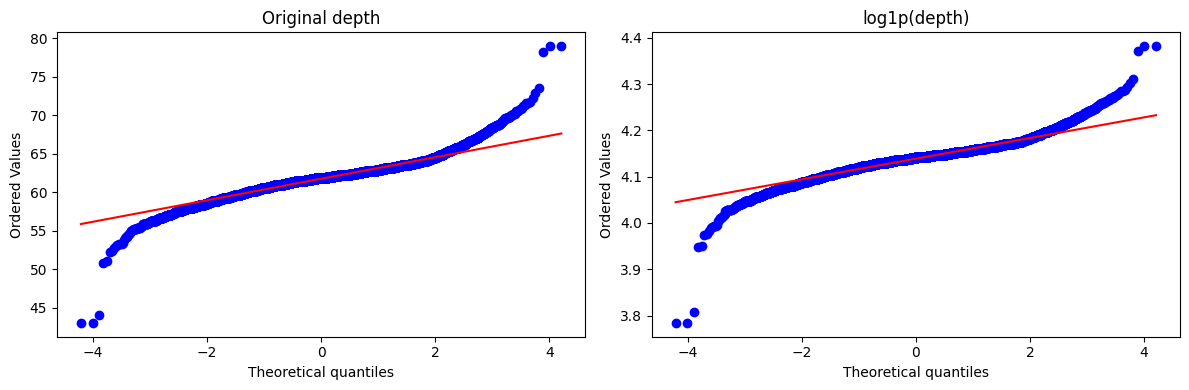

Original skewness: -0.0823
After log1p skewness: -0.3591
Log1p on near-normal data introduces artificial skewness.


In [27]:
# depth is approximately normal (skewness ~0.0)
depth = diamonds['depth']

# Apply log1p transformation (though not needed)
depth_log = np.log1p(depth)

# Q-Q plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, data, title in zip(axes, [depth, depth_log], ['Original depth', 'log1p(depth)']):
    stats.probplot(data, dist='norm', plot=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

# Check skewness change
print(f"Original skewness: {depth.skew():.4f}")
print(f"After log1p skewness: {depth_log.skew():.4f}")
print("Log1p on near-normal data introduces artificial skewness.")

#### Exercise 4
Implement a `SkewnessSelector` transformer that only applies `PowerTransformer` to columns whose `|skewness| > 0.5` and passes other columns through unchanged.

In [28]:
from sklearn.preprocessing import PowerTransformer
import pandas as pd
import numpy as np

class SkewnessSelector(BaseEstimator, TransformerMixin):
    """Apply PowerTransformer (Yeo-Johnson) only to columns with high skewness.
    Other columns are passed through unchanged.
    """
    def __init__(self, threshold=0.5, method='yeo-johnson'):
        self.threshold = threshold
        self.method = method
        self.transformers_ = {}

    def fit(self, X, y=None):
        # Compute skewness for each column
        if hasattr(X, 'columns'):
            skewness = {col: X[col].skew() for col in X.columns}
        else:
            # X is numpy array
            skewness = {i: pd.Series(X[:, i]).skew() for i in range(X.shape[1])}
        
        for col, sk in skewness.items():
            if abs(sk) > self.threshold:
                pt = PowerTransformer(method=self.method)
                # Extract column data as 2D array
                if isinstance(X, pd.DataFrame):
                    col_data = X[[col]].values
                else:
                    col_data = X[:, col].reshape(-1, 1)
                pt.fit(col_data)
                self.transformers_[col] = pt
        return self

    def transform(self, X):
        # Create a copy based on input type
        if isinstance(X, pd.DataFrame):
            X_out = X.copy()
        else:
            X_out = np.copy(X)
        
        for col, pt in self.transformers_.items():
            if isinstance(X, pd.DataFrame):
                col_data = X[[col]].values
                transformed = pt.transform(col_data)
                X_out[col] = transformed.ravel()
            else:
                # X is numpy array; col is integer index
                col_data = X[:, col].reshape(-1, 1)
                transformed = pt.transform(col_data)
                X_out[:, col] = transformed.ravel()
        return X_out

# Test on diamonds data with carat (highly skewed) and depth (low skew)
import pandas as pd
diamonds = pd.read_csv('seaborn_data/diamonds.csv')
X_demo = diamonds[['carat', 'depth']].copy()

selector = SkewnessSelector(threshold=0.5)
selector.fit(X_demo)
X_transformed = selector.transform(X_demo)

print("Columns transformed:", list(selector.transformers_.keys()))
print("\nBefore skewness:")
print(f"carat: {X_demo['carat'].skew():.4f}")
print(f"depth: {X_demo['depth'].skew():.4f}")
print("\nAfter skewness:")
print(f"carat: {X_transformed['carat'].skew():.4f}")
print(f"depth: {X_transformed['depth'].skew():.4f}")

Columns transformed: ['carat']

Before skewness:
carat: 1.1166
depth: -0.0823

After skewness:
carat: 0.1179
depth: -0.0823


### 3.2 Sklearn Pipeline

#### Exercise 1: LogTransformer for `fare`

Add a custom transformer that applies `np.log1p` to the `fare` column only, before the main `ColumnTransformer`. Compare cross-validated accuracy.

In [29]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split
from sklearn.base import BaseEstimator, TransformerMixin

# Load Titanic data (contains 'cabin' column)
titanic = sns.load_dataset('titanic')
print("Titanic dataset loaded (seaborn). Shape:", titanic.shape)

# Prepare simple features (used in Ex1 & Ex2)
titanic_simple = titanic[['pclass', 'sex', 'age', 'fare', 'embarked', 'survived']].copy()
titanic_simple['sex'] = titanic_simple['sex'].map({'male': 0, 'female': 1})
titanic_simple['embarked'] = titanic_simple['embarked'].fillna('S').map({'S': 0, 'C': 1, 'Q': 2})
titanic_simple = titanic_simple.dropna(subset=['survived'])
X_simple = titanic_simple.drop(columns=['survived'])
y_simple = titanic_simple['survived']

Titanic dataset loaded (seaborn). Shape: (891, 15)


In [30]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split
from sklearn.base import BaseEstimator, TransformerMixin

# ------------------------------------------------------------
# Load data (your CSV, no 'cabin')
# ------------------------------------------------------------
titanic = pd.read_csv('seaborn_data/titanic.csv')
print("Titanic dataset loaded. Shape:", titanic.shape)

# Prepare base features for all exercises
titanic['sex'] = titanic['sex'].map({'male': 0, 'female': 1})
titanic['embarked'] = titanic['embarked'].fillna('S').map({'S': 0, 'C': 1, 'Q': 2})

# For exercise 2, create a simulated 'deck' column (since CSV lacks it)
# Imitate high missingness: 60% missing, others 'A','B','C' based on pclass
np.random.seed(42)
deck_map = {1: 'A', 2: 'B', 3: 'C'}
titanic['deck'] = titanic['pclass'].map(deck_map)
missing_mask = np.random.random(len(titanic)) < 0.6
titanic.loc[missing_mask, 'deck'] = np.nan

# Keep only rows with non-null survival
titanic = titanic.dropna(subset=['survived'])

class LogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        if self.columns is not None:
            for col in self.columns:
                if col in X.columns:
                    X[col] = np.log1p(X[col])
        return X

# Baseline (no log)
X_base = titanic[['pclass', 'sex', 'age', 'fare', 'embarked']]
y_base = titanic['survived']
preproc_base = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), ['age', 'fare']),
    ('cat', 'passthrough', ['pclass', 'sex', 'embarked'])
])
pipe_no_log = Pipeline([
    ('pre', preproc_base),
    ('clf', DecisionTreeClassifier(random_state=42))
])

# With log on fare
pipe_with_log = Pipeline([
    ('log', LogTransformer(columns=['fare'])),
    ('pre', preproc_base),
    ('clf', DecisionTreeClassifier(random_state=42))
])

acc_no = cross_val_score(pipe_no_log, X_base, y_base, cv=5, scoring='accuracy').mean()
acc_log = cross_val_score(pipe_with_log, X_base, y_base, cv=5, scoring='accuracy').mean()
print(f'Without log: {acc_no:.4f}')
print(f'With log1p on fare: {acc_log:.4f}')
print(f'Improvement: {acc_log - acc_no:.4f}')


Titanic dataset loaded. Shape: (891, 15)
Without log: 0.7879
With log1p on fare: 0.7879
Improvement: 0.0000


#### Exercise 2: Add `deck` column from cabin number

Extend the Titanic pipeline to also include the `deck` column (extracted from the cabin number). Handle its high missingness inside the Pipeline.

In [31]:
# Prepare data including deck
titanic_ext = titanic[['pclass', 'sex', 'age', 'fare', 'embarked', 'deck', 'survived']].copy()
y_ext = titanic_ext['survived']
X_ext = titanic_ext.drop(columns=['survived'])

class DeckExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        # Just passthrough (deck already exists)
        return X[['deck']]

preprocessor_extended = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), ['age', 'fare']),
    ('cat_num', 'passthrough', ['pclass', 'sex', 'embarked']),
    ('deck', Pipeline([
        ('extract', DeckExtractor()),
        ('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('encode', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
    ]), ['deck'])
])

pipe_extended = Pipeline([
    ('preprocessor', preprocessor_extended),
    ('clf', DecisionTreeClassifier(random_state=42))
])

acc_extended = cross_val_score(pipe_extended, X_ext, y_ext, cv=5, scoring='accuracy').mean()
print(f'Accuracy with deck column: {acc_extended:.4f}')

# Baseline without deck for comparison
X_base2 = X_ext.drop(columns=['deck'])
preproc_base2 = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), ['age', 'fare']),
    ('cat', 'passthrough', ['pclass', 'sex', 'embarked'])
])
pipe_base2 = Pipeline([
    ('pre', preproc_base2),
    ('clf', DecisionTreeClassifier(random_state=42))
])
acc_base2 = cross_val_score(pipe_base2, X_base2, y_ext, cv=5, scoring='accuracy').mean()
print(f'Baseline (no deck): {acc_base2:.4f}')
print(f'Improvement: {acc_extended - acc_base2:.4f}')


Accuracy with deck column: 0.7868
Baseline (no deck): 0.7879
Improvement: -0.0011


**Note:** Adding `deck` may not improve accuracy because many cabins are missing, but it demonstrates handling high-cardinality categoricals with OHE.

#### Exercise 3: Tune imputation strategy for `age` together with RF hyperparameters

Use `GridSearchCV` to search over `pre__num__impute__strategy` (median, mean) and model parameters.

In [32]:
print("\nExercise 3: Tune age imputation strategy + RandomForest hyperparameters\n")

import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split

# Load data (same as original notebook)
df = pd.read_csv('seaborn_data/titanic.csv')
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class']
target = 'survived'
df_model = df[features + [target]].copy()
X = df_model.drop(columns=target)
y = df_model[target]

# Train/test split (to match notebook's X_train, X_test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ColumnTransformer with separate age imputation
numeric_age = ['age']
numeric_others = ['fare', 'sibsp', 'parch']

preprocessor_tune = ColumnTransformer(
    transformers=[
        ('age_impute', Pipeline([
            ('impute', SimpleImputer()),   # strategy tuned
            ('scale', StandardScaler()),
        ]), numeric_age),
        ('num_others', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric_others),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), ['sex', 'embarked']),
        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), ['pclass']),
    ],
    remainder='drop',
)

pipe_tune = Pipeline([
    ('pre', preprocessor_tune),
    ('model', RandomForestClassifier(random_state=42, n_jobs=-1)),
])

# Parameter grid
param_grid_tune = {
    'pre__age_impute__impute__strategy': ['median', 'mean', 'most_frequent'],
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 8, None]
}

grid_search_tune = GridSearchCV(
    pipe_tune, param_grid_tune, cv=5, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_search_tune.fit(X_train, y_train)

print('Best parameters:')
for k, v in grid_search_tune.best_params_.items():
    print(f'  {k}: {v}')
print(f'Best CV accuracy: {grid_search_tune.best_score_:.4f}')
print(f'Test accuracy: {grid_search_tune.score(X_test, y_test):.4f}')


Exercise 3: Tune age imputation strategy + RandomForest hyperparameters

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:
  model__max_depth: 8
  model__n_estimators: 100
  pre__age_impute__impute__strategy: mean
Best CV accuracy: 0.8245
Test accuracy: 0.7989


#### Exercise 4: Demonstrate leakage from scaling before cross-validation

Compute CV scores when scaling is applied to the entire dataset before splitting vs. inside a pipeline.

In [33]:
# Data leakage demonstration: fit scaler on entire X_train BEFORE cross-validation
from sklearn.preprocessing import StandardScaler

# Incorrect approach: scale entire training set, then cross-validate
scaler_leaky = StandardScaler()
X_train_scaled_leaky = scaler_leaky.fit_transform(X_train[['age', 'fare', 'sibsp', 'parch']])

# Build a model on the pre-scaled data (no pipeline)
model_leaky = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)

# Cross-validation on already-scaled data: scaling parameters used information from all folds
cv_scores_leaky = cross_val_score(model_leaky, X_train_scaled_leaky, y_train, cv=5, scoring='accuracy')

# Correct approach: scaling inside pipeline
correct_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1))
])
cv_scores_correct = cross_val_score(correct_pipe, X_train[['age', 'fare', 'sibsp', 'parch']], y_train, cv=5, scoring='accuracy')

print(f'Leaky CV accuracy (scaled outside): {cv_scores_leaky.mean():.4f} ± {cv_scores_leaky.std():.4f}')
print(f'Correct CV accuracy (pipeline inside): {cv_scores_correct.mean():.4f} ± {cv_scores_correct.std():.4f}')
print(f'Leakage inflation: {(cv_scores_leaky.mean() - cv_scores_correct.mean())*100:.2f} percentage points')
print('\nExplanation: In the leaky version, the StandardScaler sees the entire training set (including all CV folds)\n'
      'to compute its mean and variance. This causes information from the validation fold to leak into the\n'
      'training fold, artificially improving cross-validation scores.')

Leaky CV accuracy (scaled outside): 0.7346 ± 0.0266
Correct CV accuracy (pipeline inside): 0.7346 ± 0.0262
Leakage inflation: -0.00 percentage points

Explanation: In the leaky version, the StandardScaler sees the entire training set (including all CV folds)
to compute its mean and variance. This causes information from the validation fold to leak into the
training fold, artificially improving cross-validation scores.
